# EDA — Respiratory Disease Surveillance (PySpark)
**File:** `eda_2_09020624025.ipynb`

Notebook ini mengikuti jalur **kiri (preprocessing)** dari flowchart pribadi, dengan sumber data **Kaggle** dan pipeline **PySpark**, sebagaimana disederhanakan dari arsitektur kelompok (Kaggle → Kagglehub → RDD/DataFrame → PySpark Pipeline).

**Dataset (prototyping, sumber luar):**
- `noeyislearning/weekly-hospital-respiratory-data-and-metrics` → data mingguan RS (time series) → dipakai di `bda_2_...ipynb`
- `walterconway/covid-flu-cold-symptoms` → data gejala per pasien (numerik biner) → dipakai di `model_2_...ipynb`

**Output notebook ini:** dua dataset hasil preprocessing (siap-model) yang disimpan ke Local Storage:
`data/processed/features_symptom.parquet` dan `data/processed/features_hospital_timeseries.parquet`.

> Catatan: karena ini prototyping untuk konteks RS di Surabaya, data AS dipakai sebagai proxy metodologi (pola alur data & pipeline-nya yang direplikasi, bukan angka geografisnya).


## 0. Instalasi Library
Jalankan sekali di awal. Perlu PySpark (butuh Java 8/11/17 sudah terpasang di sistem), kagglehub untuk ingestion, pandas, dan matplotlib untuk visualisasi EDA.

In [1]:
!pip install -q pyspark==3.5.1 kagglehub pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

## 1. Import Library

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml.feature import StringIndexer, VectorAssembler

try:
    import kagglehub
except ModuleNotFoundError as e:
    print('kagglehub tidak ditemukan -> sel ingestion akan di-skip jika dataset lokal sudah ada.\n', e)


kagglehub tidak ditemukan -> sel ingestion akan di-skip jika dataset lokal sudah ada.
 No module named 'kagglehub'


## 2. Buat Spark Session
Node *PySpark Pipeline* pada diagram arsitektur — satu session dipakai di seluruh notebook (EDA, model, BDA).

In [3]:
spark = (
    SparkSession.builder
    .appName("RespiratoryDiseaseSurveillance_EDA")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/17 00:00:36 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/17 00:00:36 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/usr/local/lib/python3.12/dist-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/17 00:00:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 3. Ingestion: Kaggle → Kagglehub (`Kaggle` → `Extract Data Respiratory`)
Sel ini memakai script scraping yang sudah Anda siapkan (diperbaiki: `os.makedirs` ditambahkan supaya tidak error kalau folder belum ada, dan ditambah pengecekan supaya tidak download ulang kalau file sudah tersedia secara lokal).

Jalankan sel ini **sekali saja**. Saat diminta input:
- `Directory Kaggle` → contoh: `noeyislearning/weekly-hospital-respiratory-data-and-metrics`
- `Nama file dataset Kaggle` → contoh: `raw_weekly_hospital_respiratory_data_2020_2024` (tanpa `.csv`)


In [4]:
RAW_KAGGLE_DIR = "../data/raw/kaggle"
os.makedirs(RAW_KAGGLE_DIR, exist_ok=True)

def scrape_kaggle_datasets():
    total_dataset = int(input('Jumlah dataset: '))
    for i in range(total_dataset):
        directory = str(input('Directory Kaggle: '))
        file = str(input('Nama file dataset Kaggle (tanpa .csv): '))
        folder_target = RAW_KAGGLE_DIR
        target_path = os.path.join(folder_target, f'{file}.csv')

        if os.path.exists(target_path):
            print(f'-> {file}.csv sudah ada, skip download.')
            continue

        try:
            path = kagglehub.dataset_download(directory)
            print(f'path download: {path}')

            full_file_path = os.path.join(path, file + ".csv")
            df_kaggle = pd.read_csv(full_file_path, encoding='utf-8', low_memory=False)

            df_kaggle.to_csv(target_path, index=False)
            print(f'-> tersimpan: {target_path}')
        except Exception as e:
            print('Error Handling 01...\n', e)
            continue

_expected_files = ["large_data.csv", "raw_weekly_hospital_respiratory_data_2020_2024.csv"]
if not all(os.path.exists(os.path.join(RAW_KAGGLE_DIR, f)) for f in _expected_files):
    scrape_kaggle_datasets()
else:
    print("Dataset Kaggle sudah tersedia secara lokal, skip scraping.")


Dataset Kaggle sudah tersedia secara lokal, skip scraping.


## 4. Load Raw Data + Diamond `Structure`
Cek apakah kolom wajib tiap dataset ada. Jika **No** → `Transform to CSV` (normalisasi nama kolom) lalu lanjut. Jika **Yes** → lanjut langsung ke penyimpanan.

In [5]:
RAW_SYMPTOM_PATH = os.path.join(RAW_KAGGLE_DIR, "large_data.csv")
RAW_HOSPITAL_PATH = os.path.join(RAW_KAGGLE_DIR, "raw_weekly_hospital_respiratory_data_2020_2024.csv")

df_symptom_raw = spark.read.csv(RAW_SYMPTOM_PATH, header=True, inferSchema=True)
df_hospital_raw = spark.read.csv(RAW_HOSPITAL_PATH, header=True, inferSchema=True)

print("Symptom dataset :", df_symptom_raw.count(), "baris,", len(df_symptom_raw.columns), "kolom")
print("Hospital dataset:", df_hospital_raw.count(), "baris,", len(df_hospital_raw.columns), "kolom")


Symptom dataset : 44453 baris, 21 kolom


Hospital dataset: 12768 baris, 157 kolom


In [6]:
EXPECTED_SYMPTOM_COLS = {"TYPE"}
EXPECTED_HOSPITAL_COLS = {"Week Ending Date", "Geographic aggregation"}

def check_structure(df, expected_cols, name):
    missing = expected_cols - set(df.columns)
    ok = len(missing) == 0
    print(f"[Structure] {name}: {'OK' if ok else 'TIDAK VALID'}" + (f" | kolom hilang: {missing}" if missing else ""))
    return ok

def transform_to_csv(df):
    df_fixed = df
    for c in df.columns:
        clean_c = c.strip().replace(" ", "_")
        if clean_c != c:
            df_fixed = df_fixed.withColumnRenamed(c, clean_c)
    return df_fixed

if not check_structure(df_symptom_raw, EXPECTED_SYMPTOM_COLS, "Symptom (large_data.csv)"):
    df_symptom_raw = transform_to_csv(df_symptom_raw)

if not check_structure(df_hospital_raw, EXPECTED_HOSPITAL_COLS, "Hospital (weekly_hospital)"):
    df_hospital_raw = transform_to_csv(df_hospital_raw)


[Structure] Symptom (large_data.csv): OK
[Structure] Hospital (weekly_hospital): OK


## 5. Save by `id_disease_category` → Local Storage
Dua dataset ini mewakili dua domain masalah berbeda (klasifikasi numerik vs time-series), jadi ditandai kategorinya lalu disimpan terpisah ke Local Storage (Parquet) supaya `model_2` dan `bda_2` tahu mana yang harus di-load.

In [7]:
PROCESSED_DIR = "../data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

df_symptom_raw = df_symptom_raw.withColumn("dataset_id", F.lit("symptom_classification")) \
                                .withColumn("category", F.lit("numeric_disease"))

df_hospital_raw = df_hospital_raw.withColumn("dataset_id", F.lit("hospital_weekly")) \
                                  .withColumn("category", F.lit("time_series"))

symptom_stage1_path = os.path.join(PROCESSED_DIR, "symptom_numeric_disease.parquet")
hospital_stage1_path = os.path.join(PROCESSED_DIR, "hospital_time_series.parquet")

df_symptom_raw.write.mode("overwrite").parquet(symptom_stage1_path)
df_hospital_raw.write.mode("overwrite").parquet(hospital_stage1_path)

print("Tersimpan di Local Storage:")
print("-", symptom_stage1_path)
print("-", hospital_stage1_path)


Tersimpan di Local Storage:
- ../data/processed/symptom_numeric_disease.parquet
- ../data/processed/hospital_time_series.parquet


## 6. Load Data → Column Mapping

In [8]:
df_symptom = spark.read.parquet(symptom_stage1_path)
df_hospital = spark.read.parquet(hospital_stage1_path)

df_symptom = df_symptom.toDF(*[c.strip().lower() for c in df_symptom.columns])

HOSP_COLUMN_MAPPING = {
    "Week Ending Date": "week_date",
    "Geographic aggregation": "state",
    "Total Patients Hospitalized with COVID-19": "total_covid_hosp",
    "Total Patients Hospitalized with Influenza": "total_flu_hosp",
    "Total Patients Hospitalized with RSV": "total_rsv_hosp",
    "Number of Inpatient Beds Occupied": "inpatient_beds_occupied",
    "Number of Inpatient Beds": "inpatient_beds_total",
}
for old, new in HOSP_COLUMN_MAPPING.items():
    df_hospital = df_hospital.withColumnRenamed(old, new)

df_symptom.printSchema()


root
 |-- cough: integer (nullable = true)
 |-- muscle_aches: integer (nullable = true)
 |-- tiredness: integer (nullable = true)
 |-- sore_throat: integer (nullable = true)
 |-- runny_nose: integer (nullable = true)
 |-- stuffy_nose: integer (nullable = true)
 |-- fever: integer (nullable = true)
 |-- nausea: integer (nullable = true)
 |-- vomiting: integer (nullable = true)
 |-- diarrhea: integer (nullable = true)
 |-- shortness_of_breath: integer (nullable = true)
 |-- difficulty_breathing: integer (nullable = true)
 |-- loss_of_taste: integer (nullable = true)
 |-- loss_of_smell: integer (nullable = true)
 |-- itchy_nose: integer (nullable = true)
 |-- itchy_eyes: integer (nullable = true)
 |-- itchy_mouth: integer (nullable = true)
 |-- itchy_inner_ear: integer (nullable = true)
 |-- sneezing: integer (nullable = true)
 |-- pink_eye: integer (nullable = true)
 |-- type: string (nullable = true)
 |-- dataset_id: string (nullable = true)
 |-- category: string (nullable = true)



## 7. Diamond `Numeric & Time-series`
- **No** (symptom → bukan time-series): lanjut ke `Rename` (`type` → `disease_type`) lalu `Describe`.
- **Yes** (hospital → time-series): langsung `Describe`, kolom tanggal dipastikan bertipe `date`.

In [9]:
def is_time_series(df, date_candidates=("week_date", "date", "tanggal")):
    return any(c in df.columns for c in date_candidates)

is_symptom_ts = is_time_series(df_symptom)
is_hospital_ts = is_time_series(df_hospital)
print("Symptom dataset time-series? ->", is_symptom_ts)
print("Hospital dataset time-series? ->", is_hospital_ts)

# No -> Rename
if not is_symptom_ts:
    df_symptom = df_symptom.withColumnRenamed("type", "disease_type")

# Yes -> pastikan tipe tanggal benar
if is_hospital_ts:
    df_hospital = df_hospital.withColumn("week_date", F.to_date("week_date"))
    # Fokus ke agregat nasional (state == 'USA') sebagai satu deret waktu representatif
    df_hospital = df_hospital.filter(F.col("state") == "USA").select(
        "week_date", "total_covid_hosp", "total_flu_hosp", "total_rsv_hosp",
        "inpatient_beds_occupied", "inpatient_beds_total"
    )


Symptom dataset time-series? -> False
Hospital dataset time-series? -> True


## 8. Describe

In [10]:
print("=== Symptom dataset ===")
df_symptom.groupBy("disease_type").count().orderBy(F.desc("count")).show()
df_symptom.describe(["cough", "fever", "shortness_of_breath"]).show()

print("=== Hospital dataset (national, weekly) ===")
df_hospital.orderBy("week_date").show(5)
df_hospital.describe(["total_covid_hosp", "total_flu_hosp", "total_rsv_hosp"]).show()
print("Rentang tanggal:")
df_hospital.select(F.min("week_date"), F.max("week_date")).show()


=== Symptom dataset ===


+------------+-----+
|disease_type|count|
+------------+-----+
|         FLU|25000|
|     ALLERGY|16381|
|       COVID| 2048|
|        COLD| 1024|
+------------+-----+



+-------+------------------+-------------------+-------------------+
|summary|             cough|              fever|shortness_of_breath|
+-------+------------------+-------------------+-------------------+
|  count|             44453|              44453|              44453|
|   mean|0.5206622725125414| 0.3253998605268486|0.32389265066474704|
| stddev|0.4995785072781307|0.46852932623183713|0.46796487887678445|
|    min|                 0|                  0|                  0|
|    max|                 1|                  1|                  1|
+-------+------------------+-------------------+-------------------+

=== Hospital dataset (national, weekly) ===


+----------+----------------+--------------+--------------+-----------------------+--------------------+
| week_date|total_covid_hosp|total_flu_hosp|total_rsv_hosp|inpatient_beds_occupied|inpatient_beds_total|
+----------+----------------+--------------+--------------+-----------------------+--------------------+
|2020-08-08|           61626|             2|          NULL|                 530272|              775470|
|2020-08-15|           55005|             0|          NULL|                 534332|              781694|
|2020-08-22|           49704|             0|          NULL|                 540365|              796130|
|2020-08-29|           42551|             0|          NULL|                 545801|              804098|
|2020-09-05|           38284|             0|          NULL|                 534101|              802896|
+----------+----------------+--------------+--------------+-----------------------+--------------------+
only showing top 5 rows


+-------+------------------+-----------------+------------------+
|summary|  total_covid_hosp|   total_flu_hosp|    total_rsv_hosp|
+-------+------------------+-----------------+------------------+
|  count|               224|              224|                59|
|   mean|33851.205357142855|1932.611607142857|123.38983050847457|
| stddev|33259.400434434894|3181.782873884748| 287.4648414453708|
|    min|              1182|                0|                 0|
|    max|            152334|            16221|              1775|
+-------+------------------+-----------------+------------------+

Rentang tanggal:


+--------------+--------------+
|min(week_date)|max(week_date)|
+--------------+--------------+
|    2020-08-08|    2024-11-16|
+--------------+--------------+



## 9. Diamond `Missing Values` → `Statistical Imputation`
`large_data.csv` sudah bersih (biner 0/1, tanpa NULL). `raw_weekly_hospital_...csv` punya banyak NULL terutama di kolom RSV (pelaporan RSV baru dimulai belakangan) — NULL di sini diimputasi 0 (artinya "belum dilaporkan", bukan hilang acak).

In [11]:
null_counts_symptom = df_symptom.select(
    [F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_symptom.columns if c not in ("dataset_id","category")]
)
null_counts_symptom.show(1, truncate=False, vertical=False)

cols_to_check = ["total_covid_hosp", "total_flu_hosp", "total_rsv_hosp"]
null_counts_hospital = df_hospital.select(
    [F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in cols_to_check]
)
null_counts_hospital.show()

# Statistical Imputation (Yes branch): isi NULL numerik dgn 0 utk kolom admisi
df_hospital = df_hospital.fillna({c: 0 for c in cols_to_check})

df_hospital = df_hospital.withColumn(
    "total_respiratory_admissions",
    F.col("total_covid_hosp") + F.col("total_flu_hosp") + F.col("total_rsv_hosp")
)


+-----+------------+---------+-----------+----------+-----------+-----+------+--------+--------+-------------------+--------------------+-------------+-------------+----------+----------+-----------+---------------+--------+--------+------------+
|cough|muscle_aches|tiredness|sore_throat|runny_nose|stuffy_nose|fever|nausea|vomiting|diarrhea|shortness_of_breath|difficulty_breathing|loss_of_taste|loss_of_smell|itchy_nose|itchy_eyes|itchy_mouth|itchy_inner_ear|sneezing|pink_eye|disease_type|
+-----+------------+---------+-----------+----------+-----------+-----+------+--------+--------+-------------------+--------------------+-------------+-------------+----------+----------+-----------+---------------+--------+--------+------------+
|0    |0           |0        |0          |0         |0          |0    |0     |0       |0       |0                  |0                   |0            |0            |0         |0         |0          |0              |0       |0       |0           |
+-----+-----

+----------------+--------------+--------------+
|total_covid_hosp|total_flu_hosp|total_rsv_hosp|
+----------------+--------------+--------------+
|               0|             0|           165|
+----------------+--------------+--------------+



## 10. Diamond `Outliers Check` → `Winsorization`
Deteksi outlier pakai metode IQR pada target utama time-series (`total_respiratory_admissions`). Dataset gejala (biner 0/1) tidak relevan untuk winsorization, jadi tidak diproses di langkah ini.

In [12]:
q1, q3 = df_hospital.approxQuantile("total_respiratory_admissions", [0.25, 0.75], 0.01)
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"IQR bounds -> lower: {lower_bound:.1f}, upper: {upper_bound:.1f}")

n_outliers = df_hospital.filter(
    (F.col("total_respiratory_admissions") < lower_bound) | (F.col("total_respiratory_admissions") > upper_bound)
).count()
print("Jumlah baris outlier:", n_outliers)

# Yes -> Winsorization (cap nilai ekstrem ke batas IQR)
df_hospital = df_hospital.withColumn(
    "total_respiratory_admissions_wz",
    F.when(F.col("total_respiratory_admissions") > upper_bound, upper_bound)
     .when(F.col("total_respiratory_admissions") < lower_bound, lower_bound)
     .otherwise(F.col("total_respiratory_admissions"))
)


IQR bounds -> lower: -34253.0, upper: 90051.0


Jumlah baris outlier: 22


## 11. Feature Transformation
- **Symptom (klasifikasi)**: `StringIndexer` untuk label `disease_type`, `VectorAssembler` untuk 20 fitur gejala biner → dipakai `model_2_...ipynb` (ganti node *SVM* di flowchart dengan Logistic Regression / RandomForestClassifier, karena multi-kelas dan selaras node *Regression* di diagram arsitektur kelompok).
- **Hospital (time-series / lonjakan)**: fitur lag (`lag_1`, `lag_2`), rolling mean 4 minggu, `week_of_year`, dan target `target_next_week` (total admisi minggu berikutnya) untuk model Regression forecasting → dipakai `bda_2_...ipynb`.

In [13]:
# --- Symptom: feature transformation untuk klasifikasi ---
feature_cols = [c for c in df_symptom.columns if c not in ("disease_type", "dataset_id", "category")]

indexer = StringIndexer(inputCol="disease_type", outputCol="label")
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

df_symptom_idx = indexer.fit(df_symptom).transform(df_symptom)
df_symptom_feat = assembler.transform(df_symptom_idx)

df_symptom_feat.select("features", "label", "disease_type").show(5, truncate=False)


+--------------------------------------------------------------+-----+------------+
|features                                                      |label|disease_type|
+--------------------------------------------------------------+-----+------------+
|(20,[2,4,12,14,17,19],[1.0,1.0,1.0,1.0,1.0,1.0])              |1.0  |ALLERGY     |
|(20,[2,12,14,16,17,18,19],[1.0,1.0,1.0,1.0,1.0,1.0,1.0])      |1.0  |ALLERGY     |
|(20,[1,2,3,12,14,19],[1.0,1.0,1.0,1.0,1.0,1.0])               |1.0  |ALLERGY     |
|(20,[3,4,12,13,16,18,19],[1.0,1.0,1.0,1.0,1.0,1.0,1.0])       |1.0  |ALLERGY     |
|(20,[2,4,12,13,15,17,18,19],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|1.0  |ALLERGY     |
+--------------------------------------------------------------+-----+------------+
only showing top 5 rows


In [14]:
# --- Hospital: feature transformation untuk time-series / prediksi lonjakan ---
w = Window.orderBy("week_date")

df_hospital_feat = (
    df_hospital
    .withColumn("lag_1", F.lag("total_respiratory_admissions_wz", 1).over(w))
    .withColumn("lag_2", F.lag("total_respiratory_admissions_wz", 2).over(w))
    .withColumn("rolling_mean_4w", F.avg("total_respiratory_admissions_wz").over(w.rowsBetween(-4, -1)))
    .withColumn("week_of_year", F.weekofyear("week_date"))
    .withColumn("target_next_week", F.lead("total_respiratory_admissions_wz", 1).over(w))
)

df_hospital_feat = df_hospital_feat.dropna(subset=["lag_1", "lag_2", "rolling_mean_4w", "target_next_week"])

df_hospital_feat.select(
    "week_date", "total_respiratory_admissions_wz", "lag_1", "lag_2",
    "rolling_mean_4w", "week_of_year", "target_next_week"
).show(10)

print("Jumlah baris siap-model (time-series):", df_hospital_feat.count())


+----------+-------------------------------+-------+-------+------------------+------------+----------------+
| week_date|total_respiratory_admissions_wz|  lag_1|  lag_2|   rolling_mean_4w|week_of_year|target_next_week|
+----------+-------------------------------+-------+-------+------------------+------------+----------------+
|2020-08-22|                        49704.0|55005.0|61628.0|           58316.5|          34|         42551.0|
|2020-08-29|                        42551.0|49704.0|55005.0|55445.666666666664|          35|         38284.0|
|2020-09-05|                        38284.0|42551.0|49704.0|           52222.0|          36|         32133.0|
|2020-09-12|                        32133.0|38284.0|42551.0|           46386.0|          37|         29351.0|
|2020-09-19|                        29351.0|32133.0|38284.0|           40668.0|          38|         28925.0|
|2020-09-26|                        28925.0|29351.0|32133.0|          35579.75|          39|         30929.0|
|2020-10-0

Jumlah baris siap-model (time-series): 221


## 12. Simpan hasil Feature Transformation ke Local Storage
Output EDA ini menjadi input untuk `model_2_09020624025.ipynb` (klasifikasi) dan `bda_2_09020624025.ipynb` (time-series / prediksi lonjakan).

In [15]:
features_symptom_path = os.path.join(PROCESSED_DIR, "features_symptom.parquet")
features_hospital_path = os.path.join(PROCESSED_DIR, "features_hospital_timeseries.parquet")

df_symptom_feat.select("features", "label", "disease_type").write.mode("overwrite").parquet(features_symptom_path)
df_hospital_feat.write.mode("overwrite").parquet(features_hospital_path)

print("Tersimpan:")
print("-", features_symptom_path)
print("-", features_hospital_path)


Tersimpan:
- ../data/processed/features_symptom.parquet
- ../data/processed/features_hospital_timeseries.parquet


## 13. Visualisasi EDA tambahan

/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


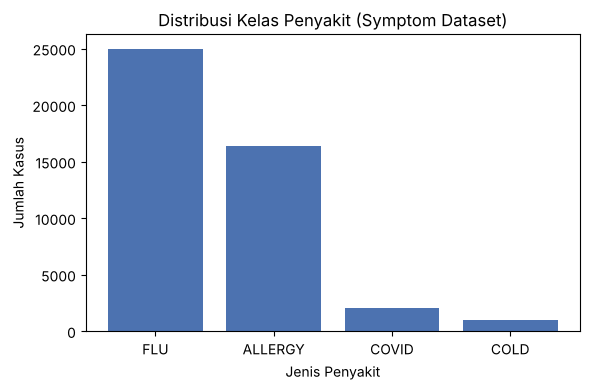

In [16]:
# Distribusi kelas penyakit (klasifikasi)
pdf_class = df_symptom.groupBy("disease_type").count().orderBy(F.desc("count")).toPandas()

plt.figure(figsize=(6,4))
plt.bar(pdf_class["disease_type"], pdf_class["count"], color="#4C72B0")
plt.title("Distribusi Kelas Penyakit (Symptom Dataset)")
plt.xlabel("Jenis Penyakit")
plt.ylabel("Jumlah Kasus")
plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


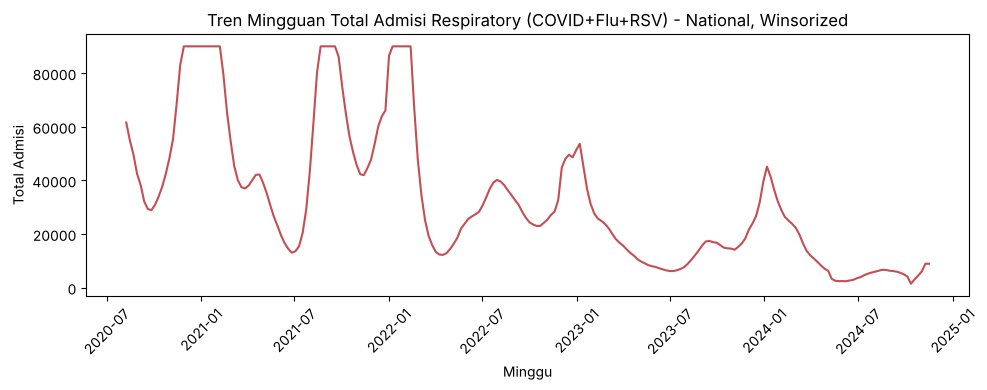

In [17]:
# Tren mingguan total admisi respiratory (national) - untuk cek pola lonjakan
pdf_trend = df_hospital.select("week_date", "total_respiratory_admissions_wz").orderBy("week_date").toPandas()

plt.figure(figsize=(10,4))
plt.plot(pdf_trend["week_date"], pdf_trend["total_respiratory_admissions_wz"], color="#C44E52")
plt.title("Tren Mingguan Total Admisi Respiratory (COVID+Flu+RSV) - National, Winsorized")
plt.xlabel("Minggu")
plt.ylabel("Total Admisi")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 14. Ringkasan
- Dua dataset sudah divalidasi strukturnya, dibersihkan (missing value + outlier/winsorization), dan ditransformasi jadi fitur siap-model.
- Output tersimpan di `data/processed/features_symptom.parquet` (untuk `model_2`) dan `data/processed/features_hospital_timeseries.parquet` (untuk `bda_2`).
- Lanjut ke `model_2_09020624025.ipynb` untuk membangun model klasifikasi (ganti SVM → Logistic Regression/RandomForestClassifier) dengan train/validation/test 70/20/10, GridSearch+CrossValidator tuning, dan evaluasi Confusion Matrix.
